## Import libraries

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support, classification_report
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential, layers
import seaborn as sns

## Read data, preprocessing, modeling

In [3]:
dataset_path = "dataset" # path to images folder

In [4]:
# params
batch_size = 16 # Uploads images in batches of 16
seed = 12 # To ensure that the split is reproducible
img_size = (256, 256)   # new images size

In [5]:
# train dataset
train_ds = image_dataset_from_directory(
    dataset_path, # Define dataset paths
    labels='inferred', # Labels are automatically inferred from subfolder names.
    label_mode='categorical', 
    batch_size=batch_size, # Uploads images in batches of 32
    image_size=img_size,
    shuffle=True, # Shuffle the images to prevent the model from learning an artificial order.
    validation_split=0.2,
    subset="training",
    seed=seed,
    color_mode="rgb" # Convert to grayscale
)

Found 1500 files belonging to 13 classes.
Using 1200 files for training.


In [6]:
# Number of classes in the dataset
num_classes = len(train_ds.class_names)

In [7]:
# validation dataset
validation_ds = image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='categorical', 
    batch_size=batch_size,
    image_size=img_size,
    shuffle=True,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    color_mode="rgb"
)

Found 1500 files belonging to 13 classes.
Using 300 files for validation.


In [8]:
# Data augmentaion
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"), 
    layers.RandomRotation(0.1),                   
    layers.RandomZoom(0.1),                       
    layers.RandomTranslation(0.1, 0.1),                     
    layers.RandomBrightness(0.2),                   
    layers.GaussianNoise(0.05), 
])

In [9]:
# Model inputs
inputs = Input(shape=(256, 256, 3))

# apply the data augmentation
x = data_augmentation(inputs)
 
# # Load ResNet50 without the last layer (include_top=False), model on images weights='imagenet'
base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=x)
base_model.trainable = False

# Add custom layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(num_classes, activation='softmax')(x)

In [10]:
# Créer le modèle final
model = Model(inputs=inputs, outputs=predictions)

In [11]:
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
early_stop = EarlyStopping(
    monitor='val_loss',      
    patience=10,              
    restore_best_weights=True  
)

In [13]:
history = model.fit(
    train_ds,  # train dataset 
    validation_data=validation_ds,  # validation dataset
    epochs=10,
    callbacks=[early_stop],
    verbose=1  # Displaying training progress
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.1342 - loss: 2.7260 - val_accuracy: 0.2100 - val_loss: 2.3327
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 172s 2s/step - accuracy: 0.2225 - loss: 2.2635 - val_accuracy: 0.3900 - val_loss: 1.9579
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 166s 2s/step - accuracy: 0.2975 - loss: 2.0973 - val_accuracy: 0.4200 - val_loss: 1.7515
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.3808 - loss: 1.8430 - val_accuracy: 0.5000 - val_loss: 1.5933
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.4333 - loss: 1.6986 - val_accuracy: 0.5367 - val_loss: 1.4938
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.4825 - loss: 1.5429 - val_accuracy: 0.5333 - val_loss: 1.4041
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.5433 - loss: 1.3913 - val_accuracy: 0.5333 - val_loss: 1.3806
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.5492 - loss: 1.3583 - val_accuracy: 0.5833 - v

## fine-tuning

In [14]:
base_model.trainable = True

# Only the final layers are fine-tuned.
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Retraining
history_finetune = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - accuracy: 0.3983 - loss: 1.9543 - val_accuracy: 0.5933 - val_loss: 1.2057
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 177s 2s/step - accuracy: 0.4725 - loss: 1.6124 - val_accuracy: 0.5900 - val_loss: 1.1769
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.5375 - loss: 1.3936 - val_accuracy: 0.6167 - val_loss: 1.1312
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 172s 2s/step - accuracy: 0.5733 - loss: 1.2963 - val_accuracy: 0.6433 - val_loss: 1.0637
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 222s 3s/step - accuracy: 0.6025 - loss: 1.2078 - val_accuracy: 0.6500 - val_loss: 1.0181
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 218s 3s/step - accuracy: 0.6292 - loss: 1.0859 - val_accuracy: 0.6767 - val_loss: 0.9489
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 197s 3s/step - accuracy: 0.6625 - loss: 0.9972 - val_accuracy: 0.6900 - val_loss: 0.9092
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.6742 - loss: 0.9349 - val_accuracy: 0.7067 - v

## Learning curves

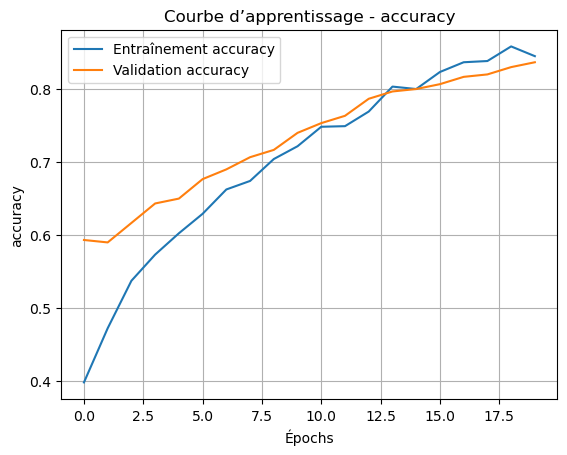

In [15]:
# Learning curve accuracy
plt.plot(history_finetune.history['accuracy'], label='Entraînement accuracy')
plt.plot(history_finetune.history['val_accuracy'], label='Validation accuracy')
plt.title('Courbe d’apprentissage - accuracy')
plt.xlabel('Épochs')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True)
plt.show()

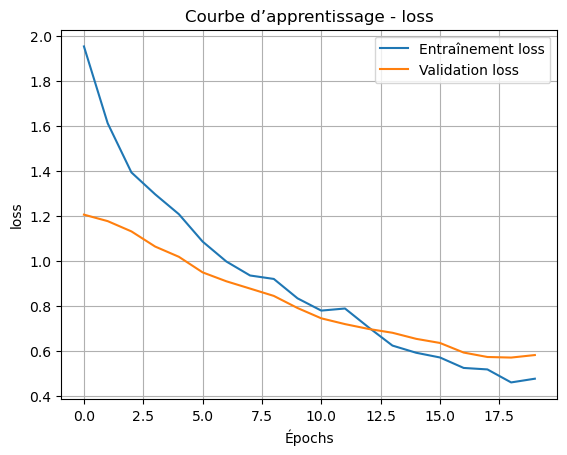

In [16]:
# Learning curve loss
plt.plot(history_finetune.history['loss'], label='Entraînement loss')
plt.plot(history_finetune.history['val_loss'], label='Validation loss')
plt.title('Courbe d’apprentissage - loss')
plt.xlabel('Épochs')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

## Evaluate Model

In [17]:
y_true, y_pred = [], []
for images, labels in validation_ds:
    probs = model.predict(images, verbose=0)
    preds = np.argmax(probs, axis=1)
    true = labels.numpy()
    
    if true.ndim > 1:  # if one-hot
        true = np.argmax(true, axis=1)
            
    y_true.extend(true)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [18]:
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=1)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1       :", f1)

Accuracy : 0.83
Precision: 0.8500410985026369
Recall   : 0.8292652541678707
F1       : 0.8303543233844752


In [25]:
labels = list(train_ds.class_names)

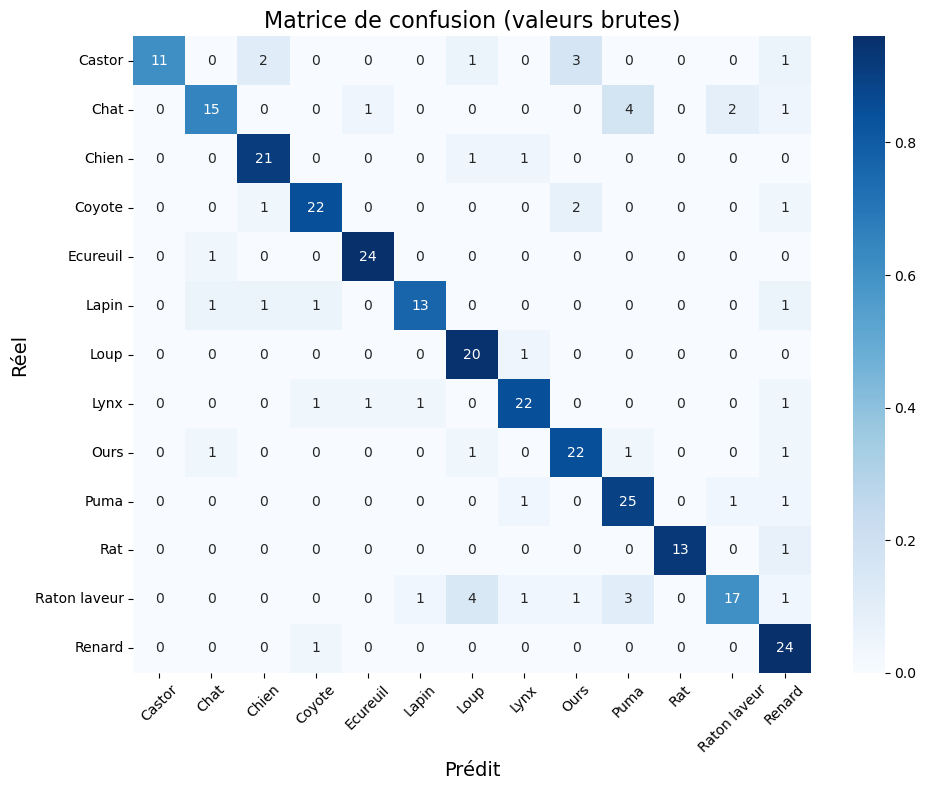

In [26]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=cm, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)

plt.xlabel("Prédit", fontsize=14)
plt.ylabel("Réel", fontsize=14)
plt.title("Matrice de confusion (valeurs brutes)", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
print(classification_report(
    y_true, y_pred,
    target_names=labels,       
    zero_division=0
))

              precision    recall  f1-score   support

      Castor       1.00      0.61      0.76        18
        Chat       0.83      0.65      0.73        23
       Chien       0.84      0.91      0.88        23
      Coyote       0.88      0.85      0.86        26
    Ecureuil       0.92      0.96      0.94        25
       Lapin       0.87      0.76      0.81        17
        Loup       0.74      0.95      0.83        21
        Lynx       0.85      0.85      0.85        26
        Ours       0.79      0.85      0.81        26
        Puma       0.76      0.89      0.82        28
         Rat       1.00      0.93      0.96        14
Raton laveur       0.85      0.61      0.71        28
      Renard       0.73      0.96      0.83        25

    accuracy                           0.83       300
   macro avg       0.85      0.83      0.83       300
weighted avg       0.84      0.83      0.83       300



## Save class names  

In [27]:
import json
with open("class_names.json", "w") as f:
    json.dump(train_ds.class_names, f)

## Saving in .keras format

In [29]:
try:
    model.save("model.keras")
    print("Model saved successfully.")
except Exception as e:
    print("Error saving model:", e)

Model saved successfully.
